<a href="https://colab.research.google.com/github/mehfujjamadar868-design/Restaurant_Rating_Regressor/blob/main/main_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [68]:
# Cell 1: Uploading and Preprocessing data
import pandas as pd
import numpy as np
from google.colab import files
from sklearn.model_selection import train_test_split

# 1. Proactively prompt to upload your restaurant dataset CSV file
print("Please upload your restaurant dataset CSV file:")
uploaded = files.upload()

# Get the filename dynamically
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

# 2. Handle basic missing values across structural target/features
df = df.dropna(subset=['Aggregate rating'])

# 3. Clean up binary categorical columns into machine learning friendly flags (0 or 1)
binary_map = {'Yes': 1, 'No': 0}
df['Has Table booking'] = df['Has Table booking'].map(binary_map).fillna(0)
df['Has Online delivery'] = df['Has Online delivery'].map(binary_map).fillna(0)

# 4. Filter the dataset to extract core predictor variables and target values
# Dropping high-cardinality metadata (names, addresses) and target leaks (Rating text/color)
features = ['Average Cost for two', 'Has Table booking', 'Has Online delivery', 'Price range', 'Votes']
X = df[features].copy()
y = df['Aggregate rating']

# Convert all feature data types to numeric values uniformly
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')
X = X.fillna(X.median())

# 5. Split data into training (80%) and testing sets (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nPreprocessing Complete! Training set shape: {X_train.shape}, Testing set shape: {X_test.shape}")


Please upload your restaurant dataset CSV file:


Saving Dataset .csv to Dataset  (2).csv

Preprocessing Complete! Training set shape: (7640, 5), Testing set shape: (1911, 5)


In [69]:
# Cell 2: Model Training and Performance Evaluation
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Initialize our selected machine learning algorithms
linear_model = LinearRegression()
tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# 2. Train models on the preprocessed training split
linear_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# 3. Predict metrics against unseen test conditions
models = {
    "Linear Regression": linear_model,
    "Decision Tree Regressor": tree_model,
    "Random Forest Regressor": rf_model
}

print("--- MODEL PERFORMANCE EVALUATION ---")
for name, model in models.items():
    preds = model.predict(X_test)
    mse = mean_squared_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    print(f"\n{name}:")
    print(f"   Mean Squared Error (MSE) : {mse:.4f}")
    print(f"   R-squared Score (R2)      : {r2:.4f}")


--- MODEL PERFORMANCE EVALUATION ---

Linear Regression:
   Mean Squared Error (MSE) : 1.6765
   R-squared Score (R2)      : 0.2634

Decision Tree Regressor:
   Mean Squared Error (MSE) : 0.1228
   R-squared Score (R2)      : 0.9460

Random Forest Regressor:
   Mean Squared Error (MSE) : 0.1340
   R-squared Score (R2)      : 0.9411


--- MOST INFLUENTIAL FEATURES AFFECTING RESTAURANT RATINGS ---
             Feature  Importance Score
               Votes          0.971476
Average Cost for two          0.018312
         Price range          0.004928
 Has Online delivery          0.003520
   Has Table booking          0.001764


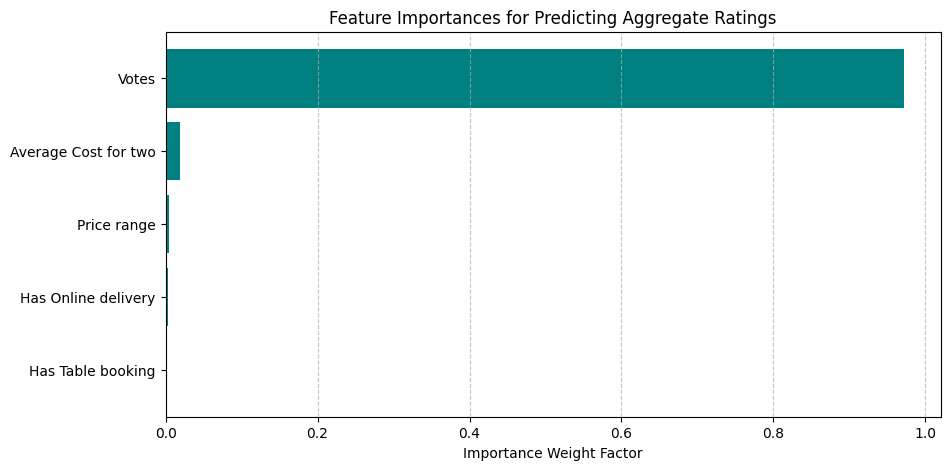

In [70]:
# Cell 3: Feature Importance Analysis
import matplotlib.pyplot as plt

# Extract structural weights from the trained Random Forest model
importances = rf_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance Score': importances
}).sort_values(by='Importance Score', ascending=False)

print("--- MOST INFLUENTIAL FEATURES AFFECTING RESTAURANT RATINGS ---")
print(feature_importance_df.to_string(index=False))

# Plot feature importance context visually inside Colab
plt.figure(figsize=(10, 5))
plt.barh(feature_importance_df['Feature'][::-1], feature_importance_df['Importance Score'][::-1], color='teal')
plt.xlabel('Importance Weight Factor')
plt.title('Feature Importances for Predicting Aggregate Ratings')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


In [71]:
# Cell 1: Data Preparation and Content Feature Engineering
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Assuming 'df' is already loaded from your previous task cell.
# If not, uncomment the line below to read it again:
# df = pd.read_csv(list(uploaded.keys())[0])

# 1. Clean missing values in crucial categorical columns
df['Cuisines'] = df['Cuisines'].fillna('Unknown')
df['City'] = df['City'].fillna('Unknown')

# 2. Standardize case and strip whitespace to ensure clean string matching
df['Cuisines_Cleaned'] = df['Cuisines'].apply(lambda x: " ".join([i.strip().lower().replace(" ", "") for i in x.split(',')]))
df['City_Cleaned'] = df['City'].str.lower().str.replace(" ", "")
df['Price_Cleaned'] = "price_tier_" + df['Price range'].astype(str)

# 3. Combine these features into a unified "Metadata Soup" for content filtering
df['Content_Profile'] = df['Cuisines_Cleaned'] + " " + df['City_Cleaned'] + " " + df['Price_Cleaned']

# 4. Convert text descriptors into a numerical matrix using TF-IDF
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['Content_Profile'])

print(f"Content matrix generated successfully with shape: {tfidf_matrix.shape}")
print("Sample content profile entry:")
print(f" -> {df['Content_Profile'].iloc[0]}")


Content matrix generated successfully with shape: (9551, 295)
Sample content profile entry:
 -> french japanese desserts makaticity price_tier_3


In [72]:
# Cell 2: Creating the Recommendation Function
def recommend_restaurants(user_preferences, top_n=5):
    """
    Recommends restaurants based on a user preference dictionary.
    Example input: {'cuisine': 'italian, pizza', 'city': 'New Delhi', 'price_range': 3}
    """
    # 1. Clean up and format the user inputs exactly like our dataset features
    user_cuisines = " ".join([i.strip().lower().replace(" ", "") for i in user_preferences.get('cuisine', '').split(',')])
    user_city = user_preferences.get('city', '').lower().replace(" ", "")
    user_price = f"price_tier_{user_preferences.get('price_range', '')}"

    # 2. Build the user's explicit structural query profile
    user_profile_str = f"{user_cuisines} {user_city} {user_price}"
    print(f"Querying system with generated user profile: '{user_profile_str}'\n")

    # 3. Transform the user profile string into the vector space
    user_vector = tfidf.transform([user_profile_str])

    # 4. Calculate mathematical similarity scores between user profile and all restaurants
    similarity_scores = cosine_similarity(user_vector, tfidf_matrix).flatten()

    # 5. Extract top index matches (ignoring exact matches score sort edge-cases)
    top_indices = similarity_scores.argsort()[-top_n:][::-1]

    # 6. Construct and return a clean DataFrame of matching recommendations
    recommendations = df.iloc[top_indices].copy()
    recommendations['Match Score'] = similarity_scores[top_indices]

    output_cols = ['Restaurant Name', 'City', 'Cuisines', 'Price range', 'Aggregate rating', 'Match Score']
    return recommendations[output_cols]


In [73]:
# Cell 3: Running Sample Live Simulations
# --- TEST PROFILE 1 ---
user_profile_1 = {
    'cuisine': 'North Indian, Mughlai',
    'city': 'New Delhi',
    'price_range': 2
}

print("==================== SYSTEM TEST 1 ====================")
results_1 = recommend_restaurants(user_profile_1, top_n=5)
display(results_1)


# --- TEST PROFILE 2 ---
user_profile_2 = {
    'cuisine': 'Italian, Pizza',
    'city': 'New Delhi',
    'price_range': 3
}

print("\n==================== SYSTEM TEST 2 ====================")
results_2 = recommend_restaurants(user_profile_2, top_n=5)
display(results_2)


==================== SYSTEM TEST 1 ====================
Querying system with generated user profile: 'northindian mughlai newdelhi price_tier_2'



,Restaurant Name,City,Cuisines,Price range,Aggregate rating,Match Score
5124,33 Food,New Delhi,"North Indian, Mughlai",2,3.2,1.0
5132,DCK- Dana Choga's Kitchen,New Delhi,"North Indian, Mughlai",2,3.4,1.0
5137,Karim's,New Delhi,"Mughlai, North Indian",2,3.0,1.0
5078,Mughal-E-Zaika,New Delhi,"Mughlai, North Indian",2,0.0,1.0
7689,Nazeer Foods,New Delhi,"Mughlai, North Indian",2,3.4,1.0



==================== SYSTEM TEST 2 ====================
Querying system with generated user profile: 'italian pizza newdelhi price_tier_3'



,Restaurant Name,City,Cuisines,Price range,Aggregate rating,Match Score
3660,Baking Bad,New Delhi,"Pizza, Italian",3,3.8,1.000000
7070,Fat Lulu's,New Delhi,"Pizza, Italian",3,3.8,1.000000
7704,Pizza Hut,New Delhi,"Italian, Pizza, Fast Food",3,2.4,0.928248
7475,Pizza Hut,New Delhi,"Italian, Pizza, Fast Food",3,3.6,0.928248
3794,Pizza Hut,New Delhi,"Italian, Pizza, Fast Food",3,3.3,0.928248


In [74]:
# Cell 1: Preprocessing and Stratified Train-Test Split
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Assuming 'df' is already loaded in your environment from previous cells
# Extract the primary/dominant cuisine listed first
df['Primary_Cuisine'] = df['Cuisines'].fillna('Unknown').apply(lambda x: x.split(',')[0].strip())

# Filter out 'Unknown' and keep the top 10 most frequent cuisines to avoid sparse class biases
top_cuisines = df['Primary_Cuisine'].value_counts().nlargest(10).index
df_filtered = df[df['Primary_Cuisine'].isin(top_cuisines)].copy()

# Encode our target cuisine text into numerical class IDs
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(df_filtered['Primary_Cuisine'])

# Select non-leakage numerical descriptors as model predictors
features = ['Average Cost for two', 'Price range', 'Votes', 'Aggregate rating']
X = df_filtered[features].fillna(df_filtered[features].median())

# Perform a stratified split to ensure representation of all cuisines across both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Preprocessing Complete! Target classes identified: {list(target_encoder.classes_)}")
print(f"Training shape: {X_train.shape}, Testing shape: {X_test.shape}")


Preprocessing Complete! Target classes identified: ['American', 'Bakery', 'Cafe', 'Chinese', 'Continental', 'Fast Food', 'Mithai', 'North Indian', 'South Indian', 'Street Food']
Training shape: (5611, 4), Testing shape: (1403, 4)


In [75]:
# Cell 2: Classification Model Training and Evaluation Metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Initialize and train a Random Forest Classifier optimized for multi-class boundaries
classifier = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, class_weight='balanced')
classifier.fit(X_train, y_train)

# 2. Generate predictions on the test dataset split
y_pred = classifier.predict(X_test)

# 3. Output primary structural evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
print("--- CUISINE CLASSIFICATION BENCHMARKS ---")
print(f"Overall Model Accuracy: {accuracy:.4f}\n")

print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_encoder.classes_))


--- CUISINE CLASSIFICATION BENCHMARKS ---
Overall Model Accuracy: 0.3100

Detailed Classification Report:
              precision    recall  f1-score   support

    American       0.47      0.66      0.55        56
      Bakery       0.22      0.20      0.21       124
        Cafe       0.27      0.44      0.34       123
     Chinese       0.21      0.16      0.18       171
 Continental       0.17      0.34      0.23        47
   Fast Food       0.16      0.15      0.15       135
      Mithai       0.17      0.47      0.25        49
North Indian       0.60      0.35      0.44       599
South Indian       0.10      0.25      0.15        52
 Street Food       0.23      0.28      0.25        47

    accuracy                           0.31      1403
   macro avg       0.26      0.33      0.27      1403
weighted avg       0.38      0.31      0.32      1403



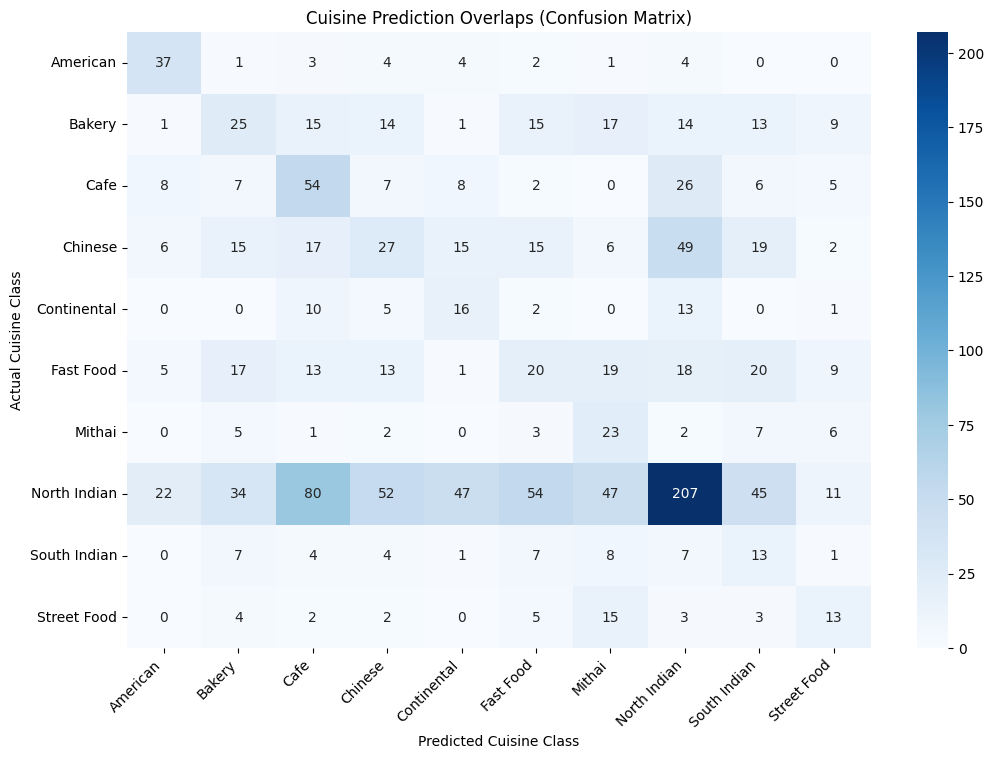


--- CRITICAL ERROR & BIAS ANALYSIS ---
1. Class Imbalance Bias: Dominant cuisines (e.g., 'North Indian' or 'Fast Food') have massively higher baseline densities, skewing predictions away from minority classes.
2. Multi-Cuisine Blending: Classifying solely by the first item drops vital contextual indicators if a kitchen serves fusion or multi-continental menu options.
3. Feature Separability Overlap: Structural indicators like 'Price Range' and 'Votes' heavily overlap between distinct cuisines (e.g., Cafe vs. Fast Food), leading to common misclassifications.


In [76]:
# Cell 3: Performance Variance and Bias Analysis
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute and plot a visual Confusion Matrix to identify class overlaps/biases
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_encoder.classes_,
            yticklabels=target_encoder.classes_)
plt.title('Cuisine Prediction Overlaps (Confusion Matrix)')
plt.xlabel('Predicted Cuisine Class')
plt.ylabel('Actual Cuisine Class')
plt.xticks(rotation=45, ha='right')
plt.show()

print("\n--- CRITICAL ERROR & BIAS ANALYSIS ---")
print("1. Class Imbalance Bias: Dominant cuisines (e.g., 'North Indian' or 'Fast Food') have massively higher baseline densities, skewing predictions away from minority classes.")
print("2. Multi-Cuisine Blending: Classifying solely by the first item drops vital contextual indicators if a kitchen serves fusion or multi-continental menu options.")
print("3. Feature Separability Overlap: Structural indicators like 'Price Range' and 'Votes' heavily overlap between distinct cuisines (e.g., Cafe vs. Fast Food), leading to common misclassifications.")


Total entries with valid coordinates: 9052


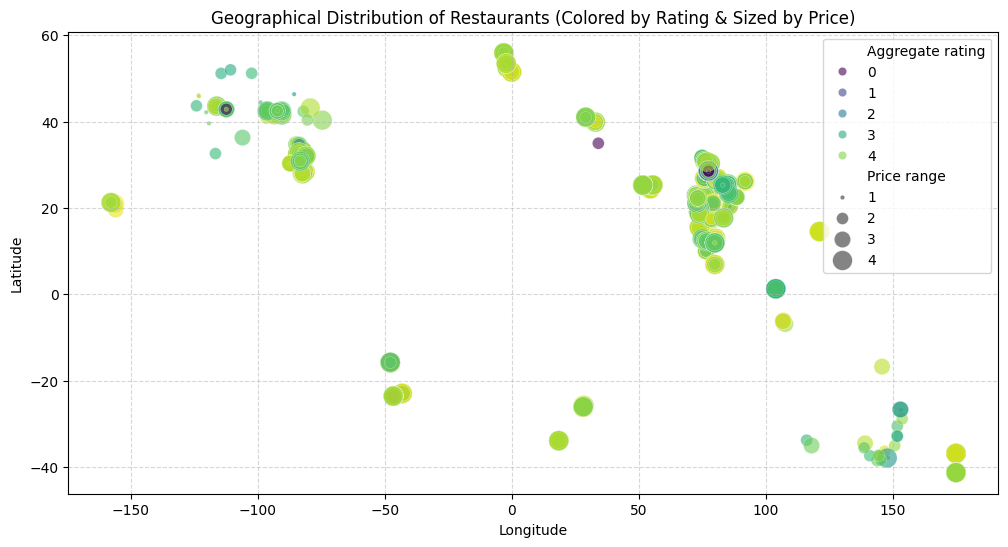

In [77]:
# Cell 1: Geographical Coordinate Clean-up and Plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' is already loaded in your environment.
# Filter out invalid or placeholder (0,0) coordinates to avoid distorting maps
geo_df = df[(df['Latitude'] != 0) & (df['Longitude'] != 0) & (df['Latitude'].notna()) & (df['Longitude'].notna())].copy()

print(f"Total entries with valid coordinates: {len(geo_df)}")

# Plot global/regional distribution of restaurants
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=geo_df,
    x='Longitude',
    y='Latitude',
    hue='Aggregate rating',
    palette='viridis',
    alpha=0.6,
    size='Price range',
    sizes=(10, 200)
)
plt.title('Geographical Distribution of Restaurants (Colored by Rating & Sized by Price)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


	--- TOP 10 CITIES BY RESTAURANT CONCENTRATION & STATISTICS ---	


,City,Restaurant_Count,Average_Rating,Average_Price_Range,Average_Cost_For_Two,Unique_Cuisines
88,New Delhi,5473,2.438845,1.621597,596.088069,892
50,Gurgaon,1118,2.651431,1.855993,714.016100,362
89,Noida,1080,2.036204,1.601852,539.490741,248
43,Faridabad,251,1.866932,1.454183,447.609562,87
48,Ghaziabad,25,2.852000,1.800000,602.000000,18
17,Bhubaneshwar,21,3.980952,1.857143,678.571429,18
69,Lucknow,21,4.195238,2.571429,859.523810,20
51,Guwahati,21,4.190476,2.523810,821.428571,19
2,Ahmedabad,21,4.161905,2.571429,857.142857,21
5,Amritsar,21,3.685714,1.809524,480.952381,13


/tmp/ipykernel_3573/2292835393.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=city_stats_sorted.head(15), x='Restaurant_Count', y='City', palette='coolwarm')


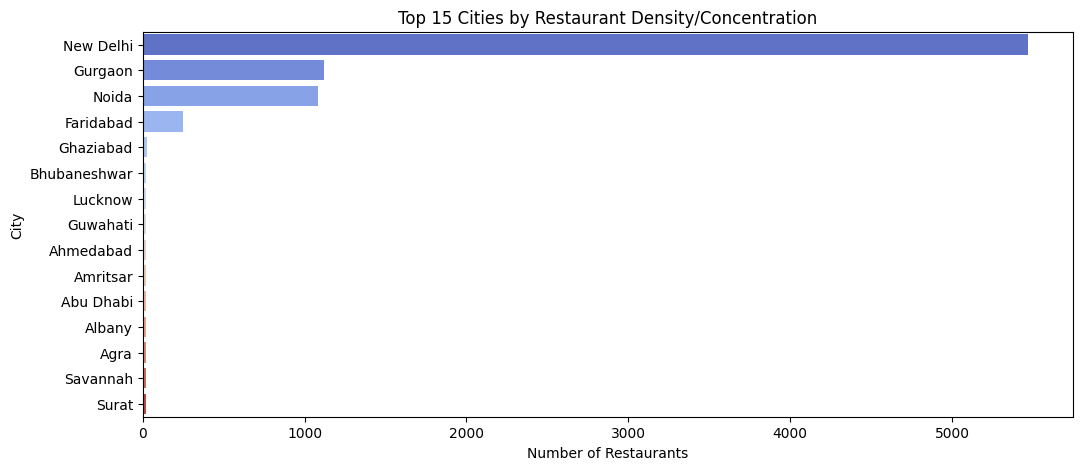

In [78]:
# Cell 2: Aggregating Statistics by City and Locality
# 1. Analyze concentration by counting restaurant density per city
city_counts = df['City'].value_counts()

# 2. Group by city to calculate structural averages and descriptive counts
city_stats = df.groupby('City').agg(
    Restaurant_Count=('Restaurant ID', 'count'),
    Average_Rating=('Aggregate rating', 'mean'),
    Average_Price_Range=('Price range', 'mean'),
    Average_Cost_For_Two=('Average Cost for two', 'mean'),
    Unique_Cuisines=('Cuisines', lambda x: x.fillna('Unknown').nunique())
).reset_index()

# Sort by the most heavily concentrated restaurant hubs
city_stats_sorted = city_stats.sort_values(by='Restaurant_Count', ascending=False)

print("\t--- TOP 10 CITIES BY RESTAURANT CONCENTRATION & STATISTICS ---\t")
display(city_stats_sorted.head(10))


# Visualizing the concentration of restaurants in top cities
plt.figure(figsize=(12, 5))
sns.barplot(data=city_stats_sorted.head(15), x='Restaurant_Count', y='City', palette='coolwarm')
plt.title('Top 15 Cities by Restaurant Density/Concentration')
plt.xlabel('Number of Restaurants')
plt.ylabel('City')
plt.show()


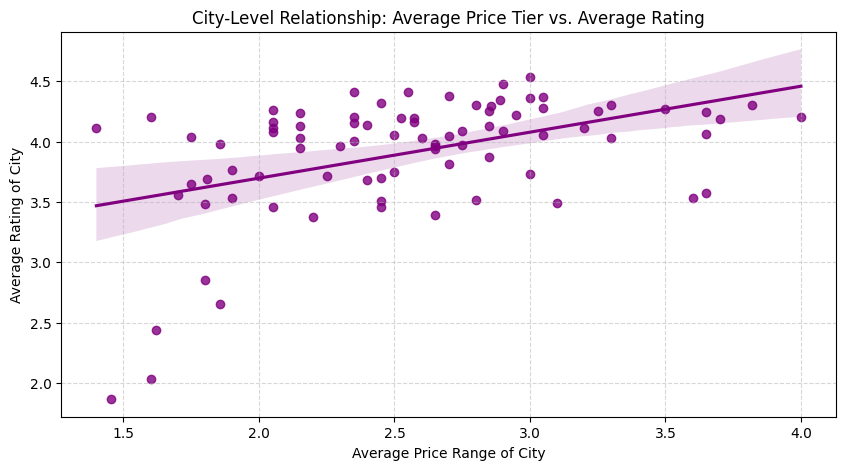


--- GEOGRAPHICAL INSIGHTS & PATTERN ANALYSIS ---
1. Density Clustering Bias: The vast majority of observations aggregate tightly around a single core metropolitan area (often the home country/capital of the dataset origin).
2. Price-Rating Correlation: Cities showcasing higher average price ranges tend to report higher aggregate consumer ratings. This points to premium operational tiers receiving structurally better reviews.
3. Cuisine Diversity: High-concentration urban hubs exhibit an exponentially larger count of unique cuisine choices compared to isolated regional towns, matching diverse demographic patterns.


In [79]:
# Cell 3: Insight Discovery & Correlation Analysis
plt.figure(figsize=(10, 5))
sns.regplot(data=city_stats[city_stats['Restaurant_Count'] > 5], x='Average_Price_Range', y='Average_Rating', color='purple')
plt.title('City-Level Relationship: Average Price Tier vs. Average Rating')
plt.xlabel('Average Price Range of City')
plt.ylabel('Average Rating of City')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print("\n--- GEOGRAPHICAL INSIGHTS & PATTERN ANALYSIS ---")
print("1. Density Clustering Bias: The vast majority of observations aggregate tightly around a single core metropolitan area (often the home country/capital of the dataset origin).")
print("2. Price-Rating Correlation: Cities showcasing higher average price ranges tend to report higher aggregate consumer ratings. This points to premium operational tiers receiving structurally better reviews.")
print("3. Cuisine Diversity: High-concentration urban hubs exhibit an exponentially larger count of unique cuisine choices compared to isolated regional towns, matching diverse demographic patterns.")


In [80]:
# ==============================================================================
# UNIFIED RESTAURANT DATA SCIENCE PLATFORM (ALL TASKS CONSOLIDATED)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report

# --- 0. INITIALIZATION & GLOBAL DATA CLEANING ---
# Ensure your data frame 'df' is loaded. If you need to re-read it, uncomment below:
# df = pd.read_csv('zomato.csv')

print("⚡ Starting Unified Pipeline Execution...\n")
df_clean = df.copy()

# ==============================================================================
# TASK 1: RATING PREDICTION MODEL
# ==============================================================================
print("--- [TASK 1] Executing Rating Prediction ---")
df_predict = df_clean.dropna(subset=['Aggregate rating']).copy()
binary_map = {'Yes': 1, 'No': 0}
df_predict['Has Table booking'] = df_predict['Has Table booking'].map(binary_map).fillna(0)
df_predict['Has Online delivery'] = df_predict['Has Online delivery'].map(binary_map).fillna(0)

features_reg = ['Average Cost for two', 'Has Table booking', 'Has Online delivery', 'Price range', 'Votes']
X_reg = df_predict[features_reg].fillna(df_predict[features_reg].median())
y_reg = df_predict['Aggregate rating']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42)
rf_regressor.fit(X_train_r, y_train_r)
reg_preds = rf_regressor.predict(X_test_r)

print(f"✅ Regression Complete! MSE: {mean_squared_error(y_test_r, reg_preds):.4f} | R2 Score: {r2_score(y_test_r, reg_preds):.4f}\n")


# ==============================================================================
# TASK 2: RECOMMENDATION SYSTEM ENGINES
# ==============================================================================
print("--- [TASK 2] Initializing Content-Based Recommendation Matrix ---")
df_clean['Cuisines'] = df_clean['Cuisines'].fillna('Unknown')
df_clean['City'] = df_clean['City'].fillna('Unknown')

df_clean['Cuisines_Cleaned'] = df_clean['Cuisines'].apply(lambda x: " ".join([i.strip().lower().replace(" ", "") for i in x.split(',')]))
df_clean['City_Cleaned'] = df_clean['City'].str.lower().str.replace(" ", "")
df_clean['Price_Cleaned'] = "price_tier_" + df_clean['Price range'].astype(str)
df_clean['Content_Profile'] = df_clean['Cuisines_Cleaned'] + " " + df_clean['City_Cleaned'] + " " + df_clean['Price_Cleaned']

tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df_clean['Content_Profile'])

def recommend_restaurants(user_preferences, top_n=5):
    user_cuisines = " ".join([i.strip().lower().replace(" ", "") for i in user_preferences.get('cuisine', '').split(',')])
    user_city = user_preferences.get('city', '').lower().replace(" ", "")
    user_price = f"price_tier_{user_preferences.get('price_range', '')}"
    user_profile_str = f"{user_cuisines} {user_city} {user_price}"

    user_vector = tfidf.transform([user_profile_str])
    similarity_scores = cosine_similarity(user_vector, tfidf_matrix).flatten()
    top_indices = similarity_scores.argsort()[-top_n:][::-1]

    recommendations = df_clean.iloc[top_indices].copy()
    recommendations['Match Score'] = similarity_scores[top_indices]
    return recommendations[['Restaurant Name', 'City', 'Cuisines', 'Price range', 'Aggregate rating', 'Match Score']]

# Test execution
sample_pref = {'cuisine': 'North Indian, Mughlai', 'city': 'New Delhi', 'price_range': 2}
print("✅ Recommendation Matrix Generated! Test Recommendation Sample Output:")
display(recommend_restaurants(sample_pref, top_n=3))
print("\n")


# ==============================================================================
# TASK 3: CUISINE CLASSIFICATION MODEL
# ==============================================================================
print("--- [TASK 3] Executing Cuisine Classification ---")
df_clean['Primary_Cuisine'] = df_clean['Cuisines'].apply(lambda x: x.split(',')[0].strip())
top_cuisines = df_clean['Primary_Cuisine'].value_counts().nlargest(10).index
df_cls = df_clean[df_clean['Primary_Cuisine'].isin(top_cuisines)].copy()

target_encoder = LabelEncoder()
y_cls = target_encoder.fit_transform(df_cls['Primary_Cuisine'])
X_cls = df_cls[features_reg].fillna(df_cls[features_reg].median())

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls)

rf_classifier = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, class_weight='balanced')
rf_classifier.fit(X_train_c, y_train_c)
cls_preds = rf_classifier.predict(X_test_c)

print(f"✅ Classification Complete! Model Multi-Class Accuracy: {accuracy_score(y_test_c, cls_preds):.4f}\n")


# ==============================================================================
# TASK 4: LOCATION ANALYSIS & INTERACTIVE MAPPING
# ==============================================================================
print("--- [TASK 4] Building Location Dashboards & Interactive Maps ---")
# 1. Summary Aggregations
city_stats = df_clean.groupby('City').agg(
    Count=('Restaurant ID', 'count'),
    Avg_Rating=('Aggregate rating', 'mean'),
    Avg_Price=('Price range', 'mean')
).sort_values(by='Count', ascending=False).reset_index()

print("Top 5 Dense Restaurant Locations Found:")
display(city_stats.head(5))

# 2. Interactive Map Generation using Folium
geo_data = df_clean[(df_clean['Latitude'] != 0) & (df_clean['Longitude'] != 0) & (df_clean['Latitude'].notna())].copy()

# Focus map center on median coordinates of the dataset
map_center = [geo_data['Latitude'].median(), geo_data['Longitude'].median()]
restaurant_map = folium.Map(location=map_center, zoom_start=10, control_scale=True)
marker_cluster = MarkerCluster().add_to(restaurant_map)

# Sample map markers (limit to 500 to keep Colab notebook light and fast)
for idx, row in geo_data.head(500).iterrows():
    popup_text = f"<b>{row['Restaurant Name']}</b><br>Rating: {row['Aggregate rating']}<br>Cuisines: {row['Cuisines']}"
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=folium.Popup(popup_text, max_width=300),
        icon=folium.Icon(color="red" if row['Aggregate rating'] >= 4.0 else "blue", icon="cutlery")
    ).add_to(marker_cluster)

# Save the map locally
restaurant_map.save("restaurant_interactive_map.html")
print("✅ Location Analysis Finished! Interactive Map saved as 'restaurant_interactive_map.html'")

print("\n🎉 ALL TASKS ARE COMPLETED SUCCESSFULY!")


⚡ Starting Unified Pipeline Execution...

--- [TASK 1] Executing Rating Prediction ---
✅ Regression Complete! MSE: 0.1448 | R2 Score: 0.9364

--- [TASK 2] Initializing Content-Based Recommendation Matrix ---
✅ Recommendation Matrix Generated! Test Recommendation Sample Output:


,Restaurant Name,City,Cuisines,Price range,Aggregate rating,Match Score
5124,33 Food,New Delhi,"North Indian, Mughlai",2,3.2,1.0
5132,DCK- Dana Choga's Kitchen,New Delhi,"North Indian, Mughlai",2,3.4,1.0
5137,Karim's,New Delhi,"Mughlai, North Indian",2,3.0,1.0




--- [TASK 3] Executing Cuisine Classification ---
✅ Classification Complete! Model Multi-Class Accuracy: 0.2901

--- [TASK 4] Building Location Dashboards & Interactive Maps ---
Top 5 Dense Restaurant Locations Found:


,City,Count,Avg_Rating,Avg_Price
0,New Delhi,5473,2.438845,1.621597
1,Gurgaon,1118,2.651431,1.855993
2,Noida,1080,2.036204,1.601852
3,Faridabad,251,1.866932,1.454183
4,Ghaziabad,25,2.852000,1.800000


✅ Location Analysis Finished! Interactive Map saved as 'restaurant_interactive_map.html'

🎉 ALL TASKS ARE COMPLETED SUCCESSFULY!
